## INTRODUCTION

Performing exploratory data analysis on a cybersecurity threat dataset to identify attack trends, severity distribution, affected devices, and geographical patterns using Prompts.


# **Prompt Used for Dataset Creation (Copilot AI)bold text**

"Generate a synthetic cybersecurity threat dataset in CSV format with more than 300 records. Include columns such as incident_id, timestamp, attack_type, attack_vector, severity, source_country, target_country, source_ip, device_affected, operating_system, target_system, protocol, port, status, detected_by, impact_level, and mitigation_action. Ensure the dataset is realistic, consistent, and suitable for data analysis. Output only the CSV content."

LOADING A **DATASET**

In [ ]:
import pandas as pd
import random

threats = ["Malware", "Phishing", "Ransomware", "DDoS", "SQL Injection", "Botnet"]
severity = ["Low", "Medium", "High", "Critical"]
countries = ["India", "USA", "UK", "Germany", "China", "Japan", "Australia"]

data = []

for i in range(300):
    data.append([
        i + 1,
        random.choice(threats),
        random.choice(severity),
        random.choice(countries),
        random.randint(1, 100)
    ])

df = pd.DataFrame(
    data,
    columns=["ID", "Threat_Type", "Severity", "Country", "Attack_Count"]
)

df.to_csv("/content/synthetic_cyber_threats_300.csv", index=False)

print("Dataset created successfully!")
df.head()

Dataset created successfully!


,ID,Threat_Type,Severity,Country,Attack_Count
0,1,Ransomware,Critical,USA,36
1,2,Malware,High,USA,8
2,3,DDoS,Low,China,35
3,4,SQL Injection,High,UK,36
4,5,Botnet,Low,Germany,71


In [ ]:
df = pd.read_csv("/content/synthetic_cyber_threats_300.csv")
df.head()

,ID,Threat_Type,Severity,Country,Attack_Count
0,1,Ransomware,Critical,USA,36
1,2,Malware,High,USA,8
2,3,DDoS,Low,China,35
3,4,SQL Injection,High,UK,36
4,5,Botnet,Low,Germany,71


In [ ]:
df.shape

(300, 5)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   ID            300 non-null    int64 
 1   Threat_Type   300 non-null    object
 2   Severity      300 non-null    object
 3   Country       300 non-null    object
 4   Attack_Count  300 non-null    int64 
dtypes: int64(2), object(3)
memory usage: 11.8+ KB


**Prompt Used for Timestamp Processing**
"Convert the timestamp column into a datetime format to enable time-based cyber attack analysis."

In [10]:
import numpy as np
import datetime

# Define a date range for random timestamps
start_date = datetime.datetime(2023, 1, 1)
end_date = datetime.datetime(2024, 1, 1)

# Generate 300 random timestamps (matching the number of rows in df)
random_timestamps = [start_date + (end_date - start_date) * np.random.random() for _ in range(len(df))]

# Add the new 'timestamp' column to the DataFrame
df['timestamp'] = random_timestamps

# Now convert the 'timestamp' column to datetime format (this step is still useful if timestamps were originally strings)
df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
print(df)

      ID    Threat_Type  Severity  Country  Attack_Count  \
0      1     Ransomware  Critical      USA            36   
1      2        Malware      High      USA             8   
2      3           DDoS       Low    China            35   
3      4  SQL Injection      High       UK            36   
4      5         Botnet       Low  Germany            71   
..   ...            ...       ...      ...           ...   
295  296  SQL Injection      High  Germany             6   
296  297     Ransomware      High       UK            30   
297  298     Ransomware       Low  Germany            46   
298  299     Ransomware  Critical       UK            92   
299  300         Botnet      High  Germany            41   

                     timestamp  
0   2023-04-11 01:34:50.890553  
1   2023-08-10 08:24:35.540928  
2   2023-04-23 06:07:28.645024  
3   2023-10-25 17:53:03.427884  
4   2023-02-04 00:45:36.608341  
..                         ...  
295 2023-06-30 07:31:49.839621  
296 2023-10-16 

**Prompt Used for Attack Type Analysis**


"Analyze the frequency of different types of cyber attacks using appropriate visualizations."

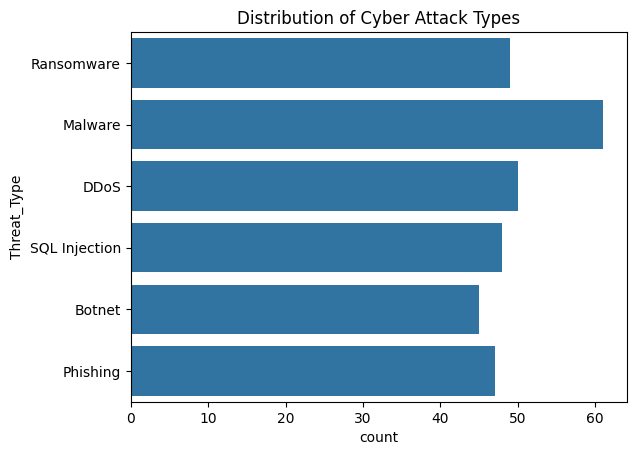

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.countplot(y="Threat_Type", data=df)
plt.title("Distribution of Cyber Attack Types")
plt.show()

Prompt Used for Severity Level **Analysis**

"Visualize the distribution of cyber attacks based on severity levels."

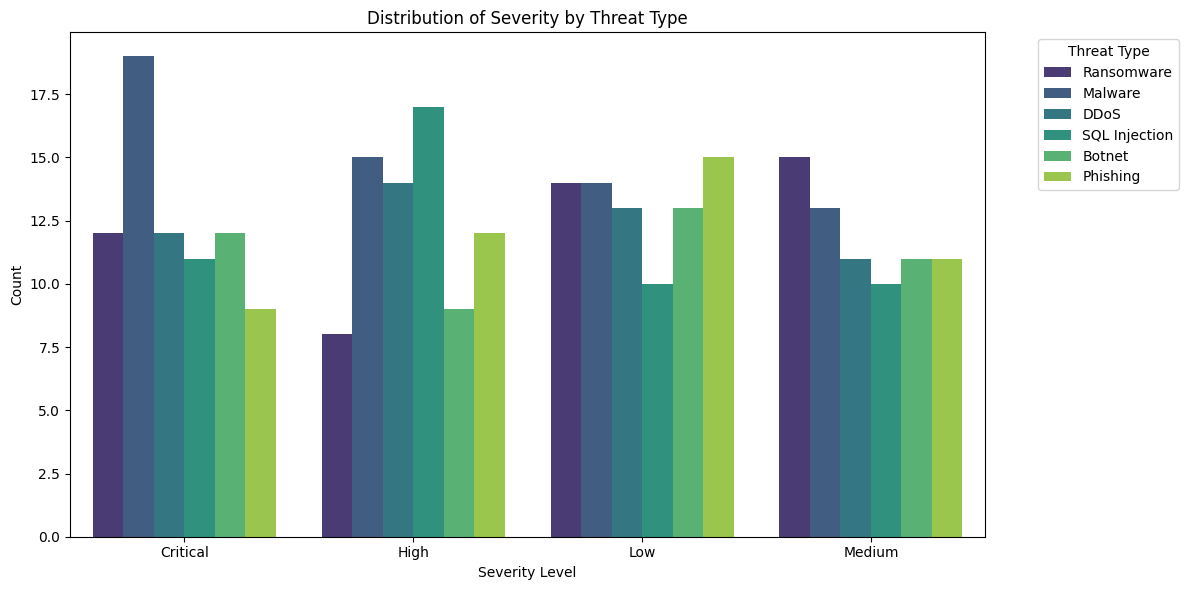

In [17]:
plt.figure(figsize=(12, 6))
sns.countplot(x='Severity', hue='Threat_Type', data=df, palette='viridis')
plt.title('Distribution of Severity by Threat Type')
plt.xlabel('Severity Level')
plt.ylabel('Count')
plt.legend(title='Threat Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Prompt Used for Device Impact Analysis**

"Identify which devices are most frequently affected by cyber attacks."

In [21]:
device_types = ['Server', 'Workstation', 'Mobile', 'IoT Device', 'Network Device']
df['device_affected'] = [random.choice(device_types) for _ in range(len(df))]
print(df.head())

   ID    Threat_Type  Severity  Country  Attack_Count  \
0   1     Ransomware  Critical      USA            36   
1   2        Malware      High      USA             8   
2   3           DDoS       Low    China            35   
3   4  SQL Injection      High       UK            36   
4   5         Botnet       Low  Germany            71   

                   timestamp device_affected  
0 2023-04-11 01:34:50.890553     Workstation  
1 2023-08-10 08:24:35.540928     Workstation  
2 2023-04-23 06:07:28.645024     Workstation  
3 2023-10-25 17:53:03.427884      IoT Device  
4 2023-02-04 00:45:36.608341  Network Device  


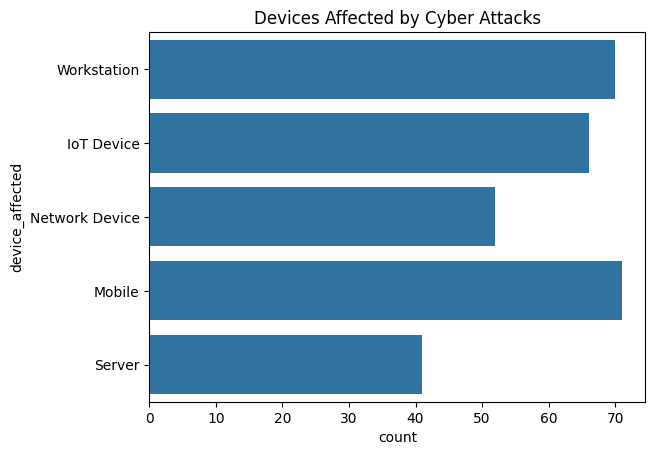

In [22]:
plt.figure()
sns.countplot(y="device_affected", data=df)
plt.title("Devices Affected by Cyber Attacks")
plt.show()

**Prompt Used for Severity by Attack Type Analysis**

"Analyze how the severity of cyber attacks varies across different attack types using visual comparison."

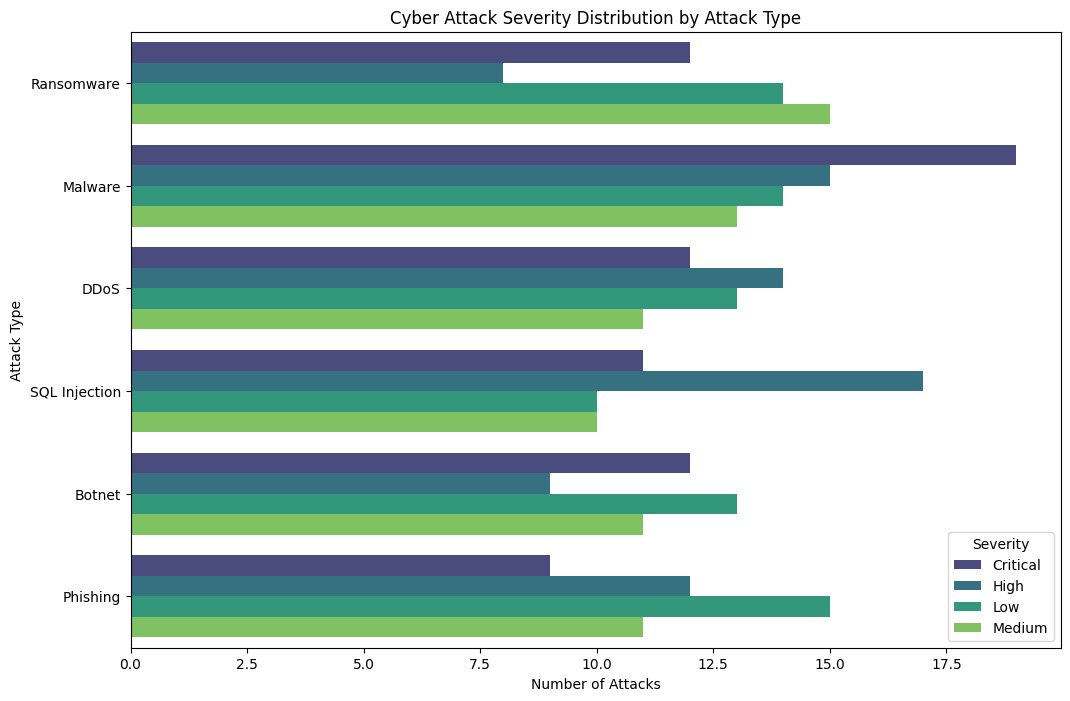

In [26]:

plt.figure(figsize=(12, 8))
sns.countplot(y="Threat_Type", hue="Severity", data=df, palette="viridis")
plt.title("Cyber Attack Severity Distribution by Attack Type")
plt.xlabel("Number of Attacks")
plt.ylabel("Attack Type")
plt.legend(title="Severity")
plt.show()


**Prompt Used for Time-Series Analysis**

"Analyze trends in cyber attacks over time using the timestamp column."

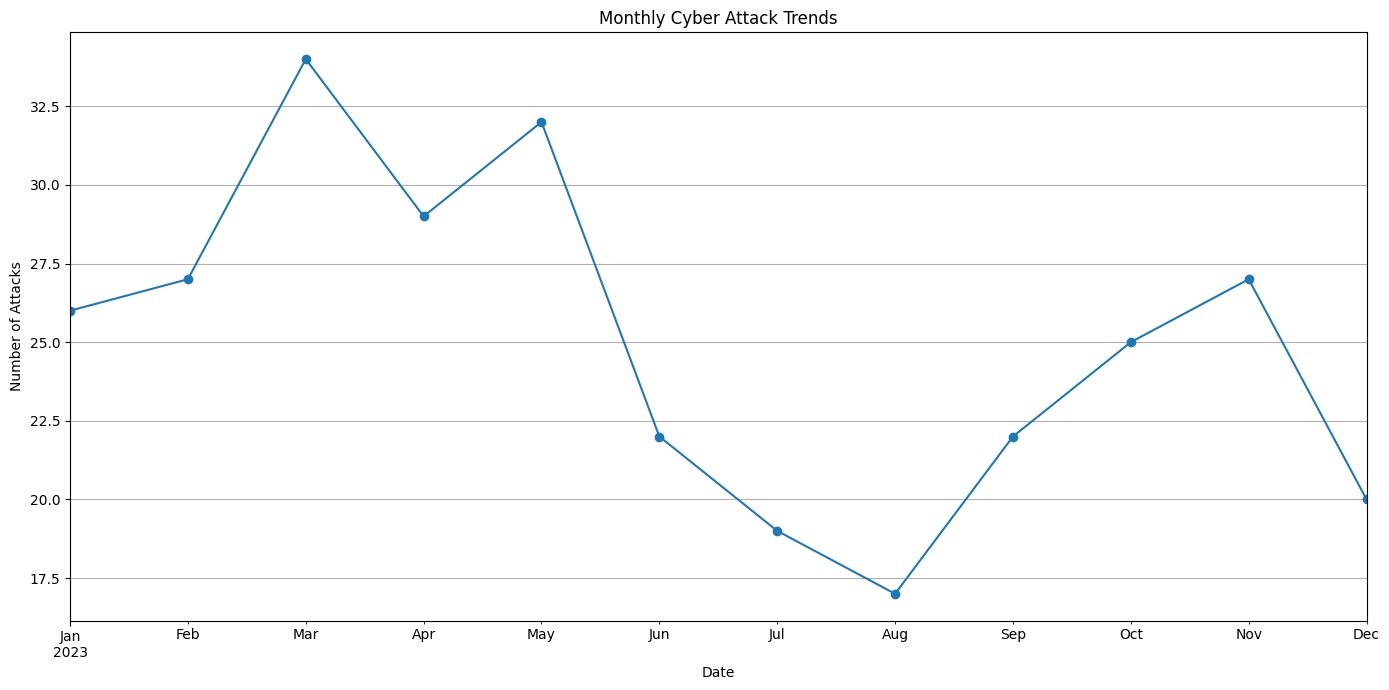

In [31]:
df_time_series = df.set_index('timestamp')
monthly_attacks = df_time_series.resample('ME').size().rename('Attack_Count')

plt.figure(figsize=(14, 7))
monthly_attacks.plot(kind='line', marker='o')
plt.title('Monthly Cyber Attack Trends')
plt.xlabel('Date')
plt.ylabel('Number of Attacks')
plt.grid(True)
plt.tight_layout()
plt.show()

**Prompt Used for Geographical Analysis**

"Analyze cyber attacks based on source countries to identify geographical patterns."

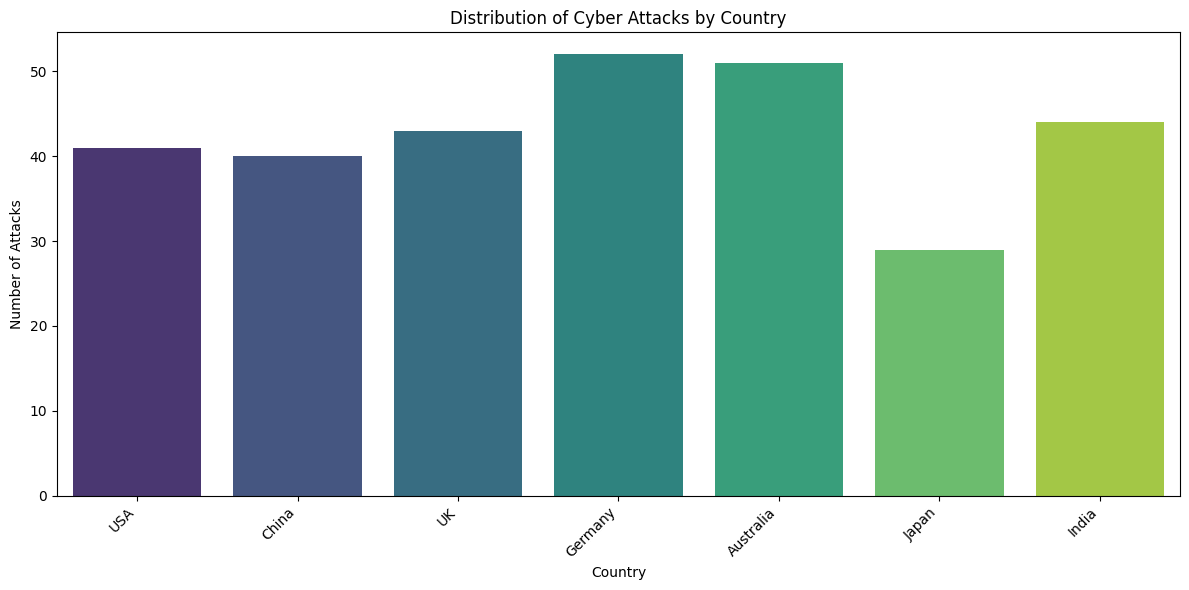

In [34]:
plt.figure(figsize=(12, 6))
sns.countplot(x='Country', data=df, palette='viridis', hue='Country', legend=False)
plt.title('Distribution of Cyber Attacks by Country')
plt.xlabel('Country')
plt.ylabel('Number of Attacks')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

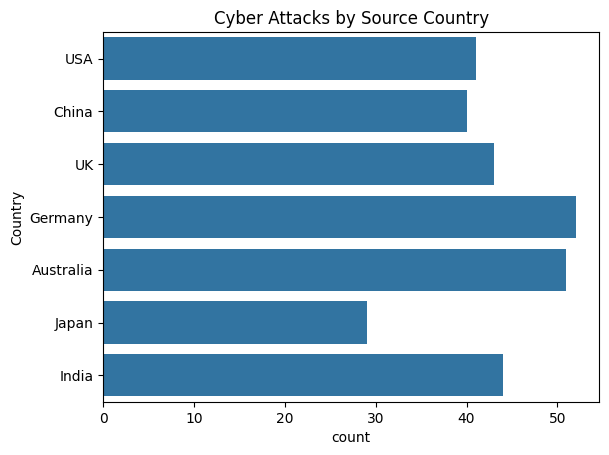

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure()
sns.countplot(y="Country", data=df)
plt.title("Cyber Attacks by Source Country")
plt.show()

**Prompt Used for Severity Trend Analysis**

"Analyze how cyber attack severity changes over time."

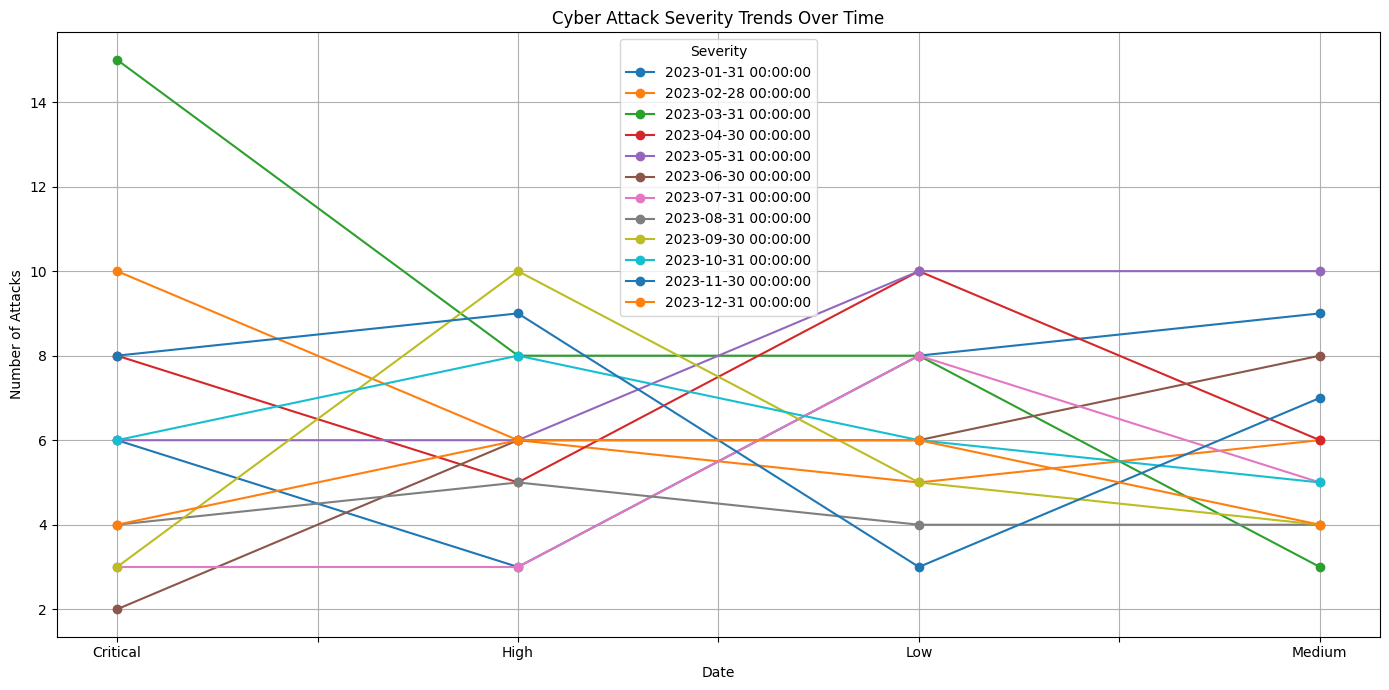

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure 'timestamp' is in datetime format and set as index for time-series analysis
# If df_time_series already exists and is correctly indexed, use it.
# Otherwise, re-create it.
if 'timestamp' not in df.columns:
    print("Error: 'timestamp' column not found in df. Please ensure it is created and properly formatted.")
else:
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    df_indexed_by_time = df.set_index('timestamp')

    # Group by Severity and resample monthly, then unstack to get severity levels as columns
    severity_trend = df_indexed_by_time.groupby('Severity').resample('ME').size().unstack(fill_value=0)

    plt.figure(figsize=(14, 7))
    severity_trend.plot(kind='line', marker='o', ax=plt.gca())
    plt.title('Cyber Attack Severity Trends Over Time')
    plt.xlabel('Date')
    plt.ylabel('Number of Attacks')
    plt.grid(True)
    plt.legend(title='Severity')
    plt.tight_layout()
    plt.show()

In [50]:
import random
df['status'] = [random.choice(['Successful', 'Blocked']) for _ in range(len(df))]
print("Added 'status' column to DataFrame.")

Added 'status' column to DataFrame.


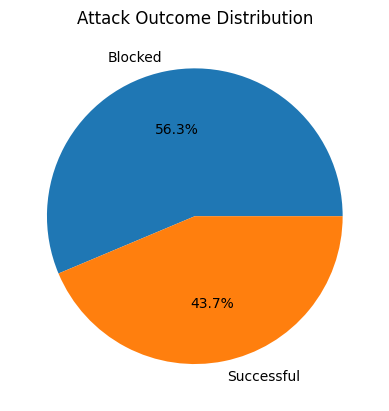

In [56]:
plt.figure()
df['status'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Attack Outcome Distribution")
plt.ylabel("")
plt.show()

**Prompt Used for Mitigation Action Analysis**

"Analyze the most commonly used mitigation actions against cyber attacks."

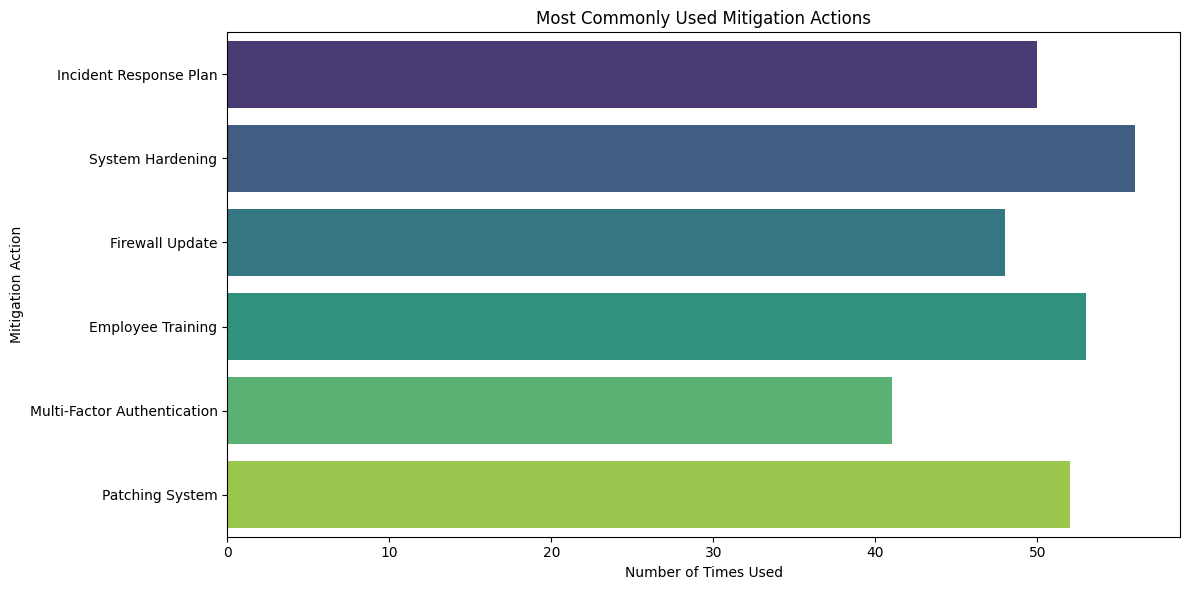

In [54]:
mitigation_actions = ['Patching System', 'Firewall Update', 'Employee Training', 'System Hardening', 'Incident Response Plan', 'Multi-Factor Authentication']
df['mitigation_action'] = [random.choice(mitigation_actions) for _ in range(len(df))]

plt.figure(figsize=(12, 6))
sns.countplot(y='mitigation_action', data=df, palette='viridis', hue='mitigation_action', legend=False)
plt.title('Most Commonly Used Mitigation Actions')
plt.xlabel('Number of Times Used')
plt.ylabel('Mitigation Action')
plt.tight_layout()
plt.show()

**Prompt Used for Detection Method Analysis**

"Analyze how cyber attacks are detected to understand effectiveness of security controls."

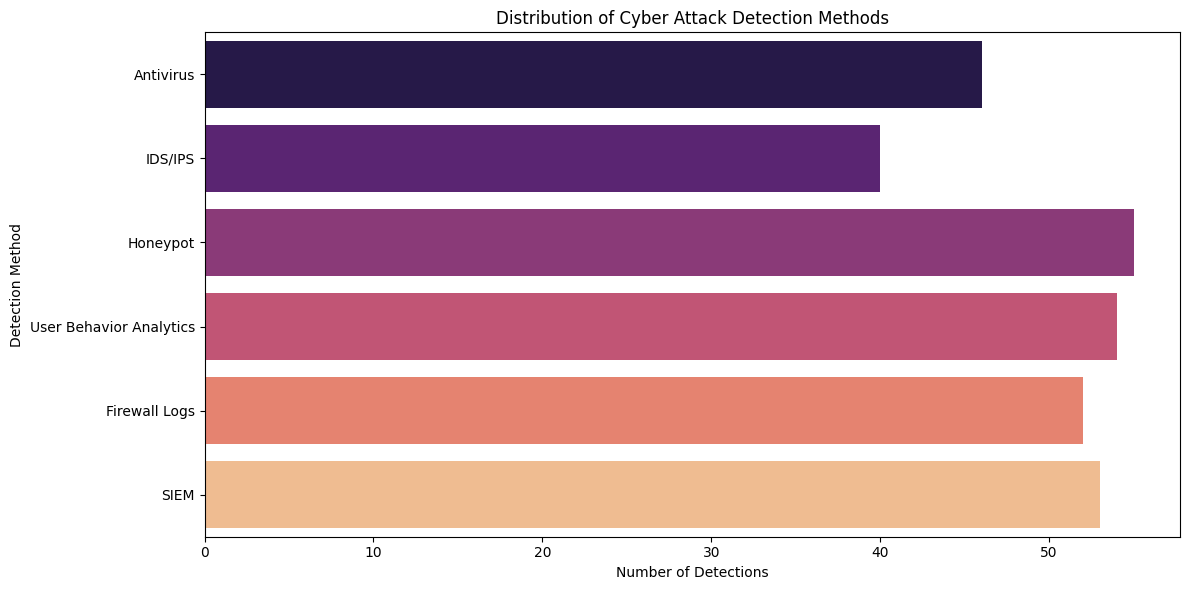

In [55]:
detection_methods = ['IDS/IPS', 'SIEM', 'Antivirus', 'Firewall Logs', 'Honeypot', 'User Behavior Analytics']
df['detection_method'] = [random.choice(detection_methods) for _ in range(len(df))]

plt.figure(figsize=(12, 6))
sns.countplot(y='detection_method', data=df, palette='magma', hue='detection_method', legend=False)
plt.title('Distribution of Cyber Attack Detection Methods')
plt.xlabel('Number of Detections')
plt.ylabel('Detection Method')
plt.tight_layout()
plt.show()

**Explanation**


This analysis was performed on a synthetic cybersecurity threat dataset generated using Copilot AI through structured prompting. The step-by-step exploratory analysis identified attack patterns based on type, severity, affected devices, geography, and time. Such analysis supports the development of interactive cyber threat visualization dashboards and informed security decision-making.

**Prompting Declaration**

This Python task was completed using AI-based prompting. Prompts were used to generate the dataset, load and process data, perform exploratory analysis, and visualize cybersecurity threats.